In [1]:
# import packages
import xarray as xr
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
#import ultimate_composite_functions as cf
import scipy.stats as stats
import sys
sys.path.append("/glade/work/smagahey/UCSB/codes/paper1_new/paper1/python_packages")
from myutils.composite_functions import select_events, var_composites, get_masks

In [2]:
import xarray as xr
import numpy as np
from scipy.stats import mannwhitneyu

# Assume early_mean and late_mean have dims: member x lat x lon

def mannwhitney_vec(a, b):
    """
    Apply mannwhitneyu along the first dimension (members)
    for two 1D arrays.
    """
    stat, p = mannwhitneyu(a, b, alternative='two-sided')
    return p


In [3]:
# dates and lat/lons
timesfut=["2070-01","2099-12"]
timespi=["1850-01","1879-12"]
tipast=["1850-01","2015-01"]
timesPD=["1980-01","2010-01"]
tissp=["2015-01","2100-01"]
ep=[-5,5,210,270] #Nino3
n34=[-5,5,190,240] # nino3.4?
n4=[-5,5,160,210]
pac=[-10,10,120,280]
regbox=[-40,40,90,300]

In [4]:
yrsfut=np.array(['2070','2071','2072','2073','2074','2075','2076','2077','2078','2079','2080','2081','2082','2083','2084','2085','2086','2087','2088','2089','2090','2091','2092','2093','2094','2095','2096','2097','2098','2099'])
yrshist=np.array(['1850','1851','1852','1853','1854','1855','1856','1857','1858','1859','1860','1861','1862','1863','1864','1865','1866','1867','1868','1869','1870','1871','1872','1873','1874','1875','1876','1877','1878','1879'])
yrshist=xr.DataArray(yrshist,dims='time')
yrsfut=xr.DataArray(yrsfut,dims='time')

In [5]:
# import file
ds=xr.open_dataset("/glade/work/smagahey/UCSB/codes/generated_files/tos_1850_2100_E3SMv1LE.nc")
tospi=ds['tos'].sel(time=slice(timespi[0],timespi[1]))
tosfut=ds['tos'].sel(time=slice(timesfut[0],timesfut[1]))
dspi=xr.open_dataset("/glade/work/smagahey/UCSB/codes/generated_files/wap_1850_1880_2N2S_120W_180W_e3smv1_lens.nc")
dsfut=xr.open_dataset("/glade/work/smagahey/UCSB/codes/generated_files/wap_2070_2100_2N2S_120W_180W_e3smv1_lens.nc")
omegapi=dspi['wap'].sel(time=slice(timespi[0],timespi[1])).sel(plev=70000).mean('lat')
omegafut=dsfut['wap'].sel(time=slice(timesfut[0],timesfut[1])).sel(plev=70000).mean('lat')

In [6]:
tospi=tospi-tospi.mean('member')
tosfut=tosfut-tosfut.mean('member')

In [7]:
enyrs_h,lnyrs_h=select_events(tospi,n34,regbox,1850,1880,timespi)
enyrs_f,lnyrs_f=select_events(tosfut,n34,regbox,2070,2100,timesfut)

In [8]:
ENom_PI,LNom_PI=var_composites(omegapi,yrshist,enyrs_h,lnyrs_h,24)
ENom_FUT,LNom_FUT=var_composites(omegafut,yrsfut,enyrs_f,lnyrs_f,24)

In [9]:
en_pi=ENom_PI.where(np.abs(ENom_PI) > 1e-4) 
ln_pi=LNom_PI.where(np.abs(LNom_PI) > 1e-4) 

In [10]:
EN_om_diff=ENom_FUT.mean('member')-ENom_PI.mean('member')
LN_om_diff=LNom_FUT.mean('member')-LNom_PI.mean('member')

In [11]:
relchange_en=(EN_om_diff/en_pi.mean('member'))*100
relchange_ln=(LN_om_diff/ln_pi.mean('member'))*100

In [12]:
#pct_en = relchange_en.fillna(0) #.interpolate_na(dim="time").interpolate_na(dim="lon")
#pct_ln = relchange_ln.fillna(0) #interpolate_na(dim="time").interpolate_na(dim="lon")

In [13]:
mask = np.abs(LNom_PI) < 1e-4
pct = ((LN_om_diff / (LNom_PI + 1e-6)) * 100).where(~mask)
pct_ln = pct.fillna(0)  # if you want no holes when plotting

In [14]:
#mask = np.abs(ENom_PI) < 1e-4
pct = ((EN_om_diff / (ENom_PI.std('time') + 1e-6))) #.where(~mask)
pct_en = pct.fillna(0)  # if you want no holes when plotting

In [15]:
vmi=-0.01
vma=0.01

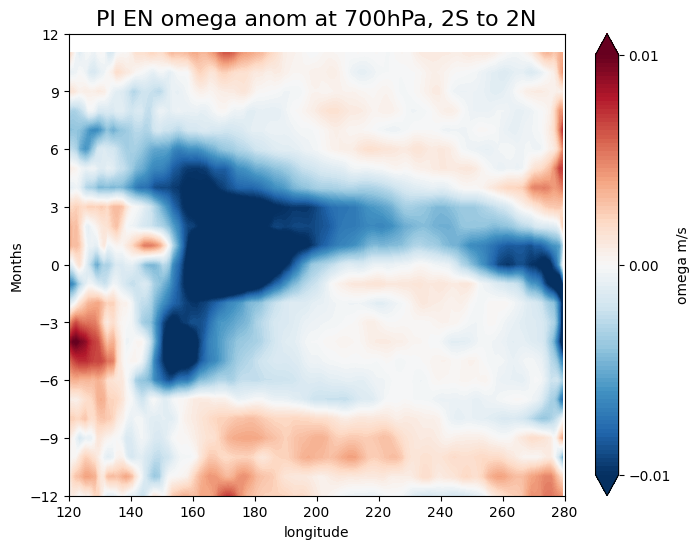

In [16]:
fig=plt.figure(figsize=(8,6))
ax = fig.add_subplot(1,1,1)
levels = np.linspace(vmi, vma, 101)
#im=ax.pcolormesh(EN_om_diff.lon,EN_om_diff.time,EN_om_diff,cmap="RdBu_r",vmin=vmi,vmax=vma)
im=plt.contourf(EN_om_diff.lon,EN_om_diff.time,ENom_PI.mean('member'),levels=levels,cmap='RdBu_r',vmin=vmi,vmax=vma,extend='both')
plt.title("PI EN omega anom at 700hPa, 2S to 2N",fontsize=16)
#ax.set_extent([120,280, 1000, 0])
plt.xlim(120,280)
#plt.ylim(100000,0)
plt.xlabel('longitude')
plt.ylabel('Months')
ax.set_yticks([-12,-9,-6,-3,0,3,6,9,12])
#bounds1=np.linspace(-3,3,50)
cbar1 = plt.colorbar(im,label='omega m/s', orientation="vertical",extend = 'both',ax=ax,drawedges=False)
#cbar1=plt.colorbar(im)
cbar1.set_ticks([vmi,0,vma])
#cbar1.set_ticklabels([vmi,0,vma])

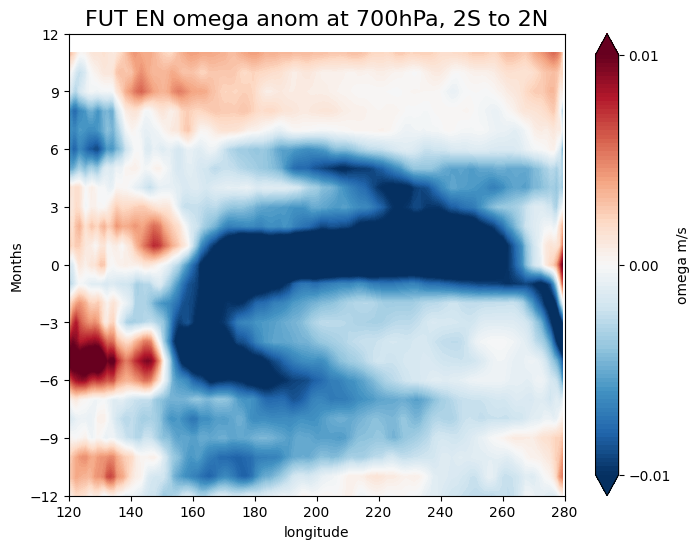

In [17]:
fig=plt.figure(figsize=(8,6))
ax = fig.add_subplot(1,1,1)
levels = np.linspace(vmi, vma, 101)
#im=ax.pcolormesh(EN_om_diff.lon,EN_om_diff.time,EN_om_diff,cmap="RdBu_r",vmin=vmi,vmax=vma)
im=plt.contourf(EN_om_diff.lon,EN_om_diff.time,ENom_FUT.mean('member'),levels=levels,cmap='RdBu_r',vmin=vmi,vmax=vma,extend='both')
plt.title("FUT EN omega anom at 700hPa, 2S to 2N",fontsize=16)
#ax.set_extent([120,280, 1000, 0])
plt.xlim(120,280)
#plt.ylim(100000,0)
plt.xlabel('longitude')
plt.ylabel('Months')
ax.set_yticks([-12,-9,-6,-3,0,3,6,9,12])
#bounds1=np.linspace(-3,3,50)
cbar1 = plt.colorbar(im,label='omega m/s', orientation="vertical",extend = 'both',ax=ax,drawedges=False)
#cbar1=plt.colorbar(im)
cbar1.set_ticks([vmi,0,vma])
#cbar1.set_ticklabels([vmi,0,vma])

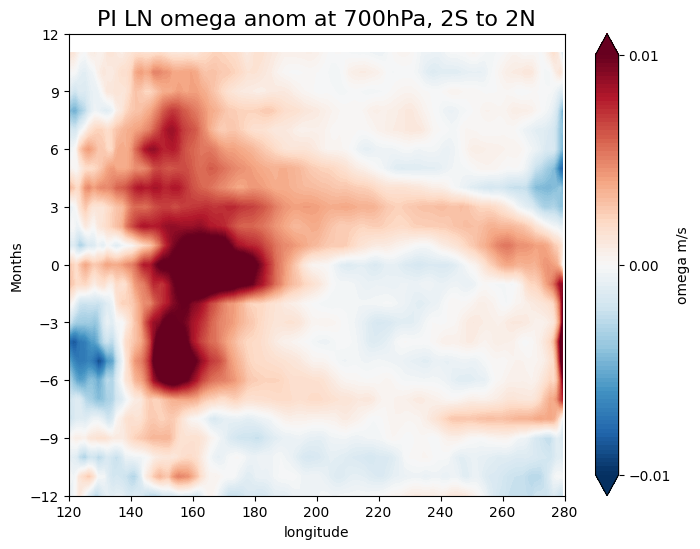

In [18]:
fig=plt.figure(figsize=(8,6))
ax = fig.add_subplot(1,1,1)
levels = np.linspace(vmi, vma, 101)
#im=ax.pcolormesh(EN_om_diff.lon,EN_om_diff.time,EN_om_diff,cmap="RdBu_r",vmin=vmi,vmax=vma)
im=plt.contourf(EN_om_diff.lon,EN_om_diff.time,LNom_PI.mean('member'),levels=levels,cmap='RdBu_r',vmin=vmi,vmax=vma,extend='both')
plt.title("PI LN omega anom at 700hPa, 2S to 2N",fontsize=16)
#ax.set_extent([120,280, 1000, 0])
plt.xlim(120,280)
#plt.ylim(100000,0)
plt.xlabel('longitude')
plt.ylabel('Months')
ax.set_yticks([-12,-9,-6,-3,0,3,6,9,12])
#bounds1=np.linspace(-3,3,50)
cbar1 = plt.colorbar(im,label='omega m/s', orientation="vertical",extend = 'both',ax=ax,drawedges=False)
#cbar1=plt.colorbar(im)
cbar1.set_ticks([vmi,0,vma])
#cbar1.set_ticklabels([vmi,0,vma])

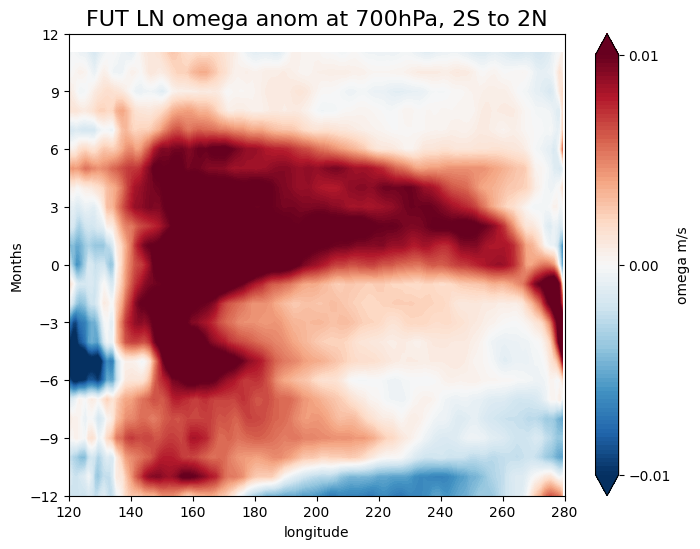

In [19]:
fig=plt.figure(figsize=(8,6))
ax = fig.add_subplot(1,1,1)
levels = np.linspace(vmi, vma, 101)
#im=ax.pcolormesh(EN_om_diff.lon,EN_om_diff.time,EN_om_diff,cmap="RdBu_r",vmin=vmi,vmax=vma)
im=plt.contourf(EN_om_diff.lon,EN_om_diff.time,LNom_FUT.mean('member'),levels=levels,cmap='RdBu_r',vmin=vmi,vmax=vma,extend='both')
plt.title("FUT LN omega anom at 700hPa, 2S to 2N",fontsize=16)
#ax.set_extent([120,280, 1000, 0])
plt.xlim(120,280)
#plt.ylim(100000,0)
plt.xlabel('longitude')
plt.ylabel('Months')
ax.set_yticks([-12,-9,-6,-3,0,3,6,9,12])
#bounds1=np.linspace(-3,3,50)
cbar1 = plt.colorbar(im,label='omega m/s', orientation="vertical",extend = 'both',ax=ax,drawedges=False)
#cbar1=plt.colorbar(im)
cbar1.set_ticks([vmi,0,vma])
#cbar1.set_ticklabels([vmi,0,vma])

In [20]:
def stipple_mask(pival,futval,alpha,x1,y1):
    pvals = xr.apply_ufunc(
    mannwhitney_vec,
    pival,futval,
    input_core_dims=[['member'], ['member']],
    vectorize=True,
    dask='parallelized',  # optional if using dask
    output_dtypes=[float],
    )
    
    sig = pvals < alpha

    x,y = np.meshgrid(x1, y1)
    x1_sig = x[sig.values]
    y1_sig = y[sig.values]
    
    return x1_sig, y1_sig

In [21]:
lons_sigen,times_sigen=stipple_mask(ENom_PI,ENom_FUT, 0.05,ENom_PI.lon,ENom_PI.time)

In [22]:
#lons_sig

In [23]:
vmi=-.01
vma=.01

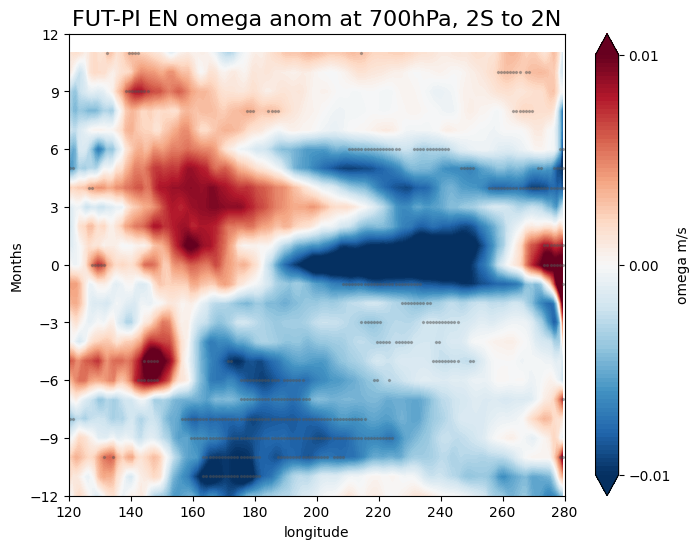

In [24]:
fig=plt.figure(figsize=(8,6))
ax = fig.add_subplot(1,1,1)
levels = np.linspace(-0.01, 0.01, 101)
#im=ax.pcolormesh(EN_om_diff.lon,EN_om_diff.time,EN_om_diff,cmap="RdBu_r",vmin=vmi,vmax=vma)
im=plt.contourf(EN_om_diff.lon,EN_om_diff.time,EN_om_diff,levels=levels,cmap='RdBu_r',vmin=vmi,vmax=vma,extend='both')
plt.title("FUT-PI EN omega anom at 700hPa, 2S to 2N",fontsize=16)
#ax.set_extent([120,280, 1000, 0])
plt.xlim(120,280)
#plt.ylim(100000,0)
ax.scatter(lons_sigen, times_sigen, color='#555555', s=2, marker='x', alpha=0.5)
plt.xlabel('longitude')
plt.ylabel('Months')
ax.set_yticks([-12,-9,-6,-3,0,3,6,9,12])
#bounds1=np.linspace(-3,3,50)
cbar1 = plt.colorbar(im,label='omega m/s', orientation="vertical",extend = 'both',ax=ax,drawedges=False)
#cbar1=plt.colorbar(im)
cbar1.set_ticks([vmi,0,vma])
#cbar1.set_ticklabels([vmi,0,vma])

In [25]:
lons_sig,times_sig=stipple_mask(LNom_PI,LNom_FUT, 0.05,ENom_PI.lon,ENom_PI.time)

In [26]:
monthlabs=['Dec$^{-1}$','Mar$^{0}$','Jun$^{0}$','Sept$^{0}$','Dec$^{0}$','Mar$^{1}$','Jun$^{1}$','Sept$^{1}$','Dec$^{1}$']


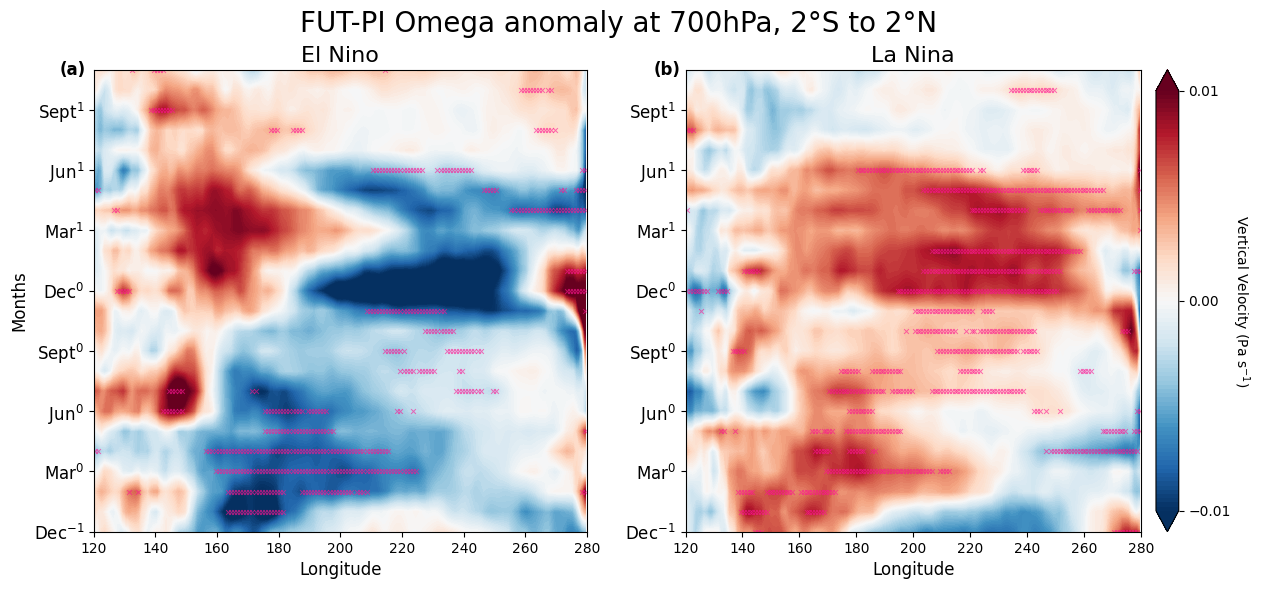

In [37]:
import matplotlib.patheffects as pe

fig=plt.figure(figsize=(14,6))
ax = fig.add_subplot(1,2,1)
levels = np.linspace(-0.01, 0.01, 101)
#im=ax.pcolormesh(EN_om_diff.lon,EN_om_diff.time,EN_om_diff,cmap="RdBu_r",vmin=vmi,vmax=vma)
im=plt.contourf(EN_om_diff.lon,EN_om_diff.time,EN_om_diff,levels=levels,cmap='RdBu_r',vmin=vmi,vmax=vma,extend='both')
plt.title("El Nino",fontsize=16)
#ax.set_extent([120,280, 1000, 0])
plt.xlim(120,280)
#plt.ylim(100000,0)
ax.scatter(lons_sigen, times_sigen, color='deeppink', s=12, marker='x',linewidths=.7, alpha=0.6)
plt.xlabel('Longitude',fontsize=12)
plt.ylabel('Months', fontsize=12)
ax.set_yticks([-12,-9,-6,-3,0,3,6,9,12])
ax.set_yticklabels(monthlabs,fontsize=12)
ax.set_ylim(-12, 11)  # or whatever your month range is

ax1 = fig.add_subplot(1,2,2)
levels = np.linspace(-0.01, 0.01, 101)
#im=ax.pcolormesh(EN_om_diff.lon,EN_om_diff.time,EN_om_diff,cmap="RdBu_r",vmin=vmi,vmax=vma)
im=plt.contourf(LN_om_diff.lon,LN_om_diff.time,LN_om_diff,levels=levels,cmap='RdBu_r',vmin=-.01,vmax=.01,extend='both')
plt.title("La Nina",fontsize=16)
#ax.set_extent([120,280, 1000, 0])
plt.xlim(120,280)
#plt.ylim(100000,0)
plt.xlabel('Longitude', fontsize=12)
#plt.ylabel('Months')
ax1.scatter(lons_sig, times_sig, color='deeppink', s=12, marker='x',linewidths=.7, alpha=0.6)

ax1.set_yticks([-12,-9,-6,-3,0,3,6,9,12])
ax1.set_yticklabels(monthlabs, fontsize=12)
ax1.set_ylim(-12, 11)  # or whatever your month range is
bounds1=np.linspace(-.01,.01,50)
from mpl_toolkits.axes_grid1 import make_axes_locatable

divider = make_axes_locatable(ax1)  # ax2 = right panel
cax = divider.append_axes("right", size="5%", pad=0.15)
cbar = plt.colorbar(im, cax=cax)
cbar.set_ticks([-.01, 0, .01])
cbar.set_label('Vertical Velocity (Pa s$^{-1}$)', rotation=270, labelpad=15)
for axis, label in zip([ax, ax1], ['(a)', '(b)']):
    axis.text(-.07, 1.02, label, transform=axis.transAxes,
              fontsize=12, fontweight='bold', va='top', ha='left')
plt.suptitle('FUT-PI Omega anomaly at 700hPa, 2°S to 2°N', fontsize=20)   
plt.savefig('hovmoller_fig8.png')